In [1]:
#pip3 install PyWavelets
# pip install matplotlib

In [2]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import pywt
import pywt.data
import numpy as np
import cv2
import math

In [3]:
# some utility functions for data scaling and visualization 

np.random.seed(0)

def to_float01(img):
    img = img.astype(np.float64, copy=False)
    mn, mx = float(img.min()), float(img.max())
    if mx > mn:
        img = (img - mn) / (mx - mn)
    else:
        img = np.zeros_like(img, dtype=np.float64)
    return img

def show(img, title=None, cmap="gray", vmin=0, vmax=1):
    plt.figure(figsize=(6, 6))
    plt.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    plt.axis("off")
    if title:
        plt.title(title)
    plt.tight_layout()
    plt.show()

Load the original image data. You will have to replace this for your own image. 

Image source: Camera image from pywt.data
Shape: (512, 512) min/max: 0.0 1.0


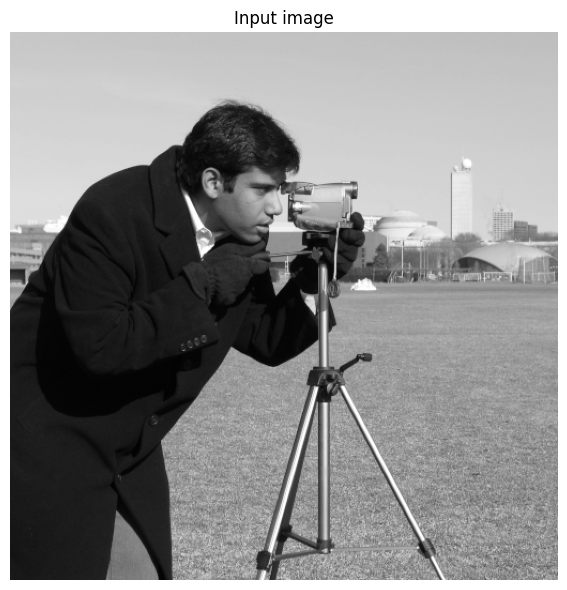

In [4]:
# load image 

img = pywt.data.camera()
img = to_float01(img)
source = "Camera image from pywt.data"

# # load your own image 
# img = mpimg.imread("own_image.jpg")  # replace with your image path
# img = to_float01(img)
# source = "own image"


print("Image source:", source)
print("Shape:", img.shape, "min/max:", img.min(), img.max())
show(img, "Input image")

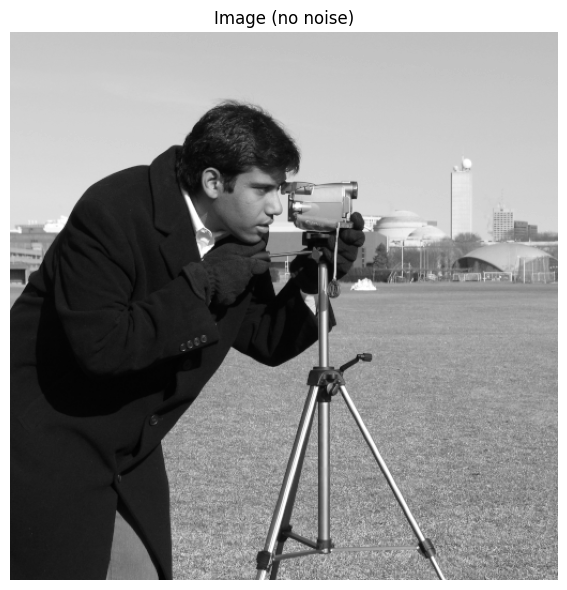

In [5]:
sigma = 0
noisy = np.clip(img + sigma*np.random.randn(*img.shape), 0, 1)
show(noisy, f"Noisy image (sigma={sigma})" if sigma > 0 else "Image (no noise)")

Noise Sigma: 0.006 -> Selected Level: 1
Noise Sigma: 0.096 -> Selected Level: 2
Noise Sigma: 0.205 -> Selected Level: 3
Noise Sigma: 0.334 -> Selected Level: 4


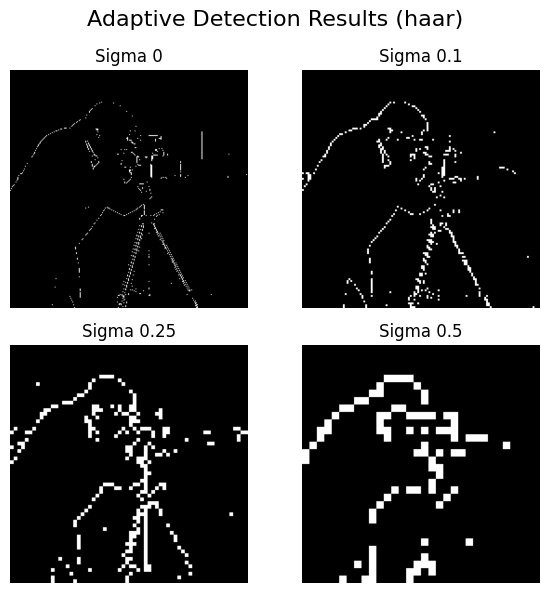

Noise Sigma: 0.005 -> Selected Level: 1
Noise Sigma: 0.096 -> Selected Level: 2
Noise Sigma: 0.205 -> Selected Level: 3
Noise Sigma: 0.332 -> Selected Level: 4


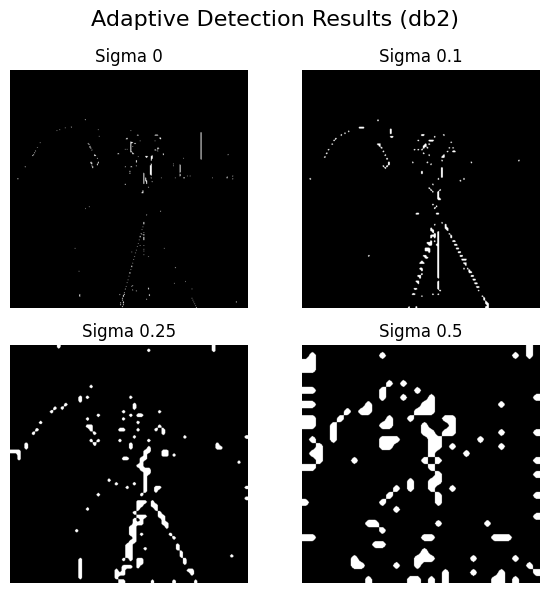

Noise Sigma: 0.005 -> Selected Level: 1
Noise Sigma: 0.095 -> Selected Level: 2
Noise Sigma: 0.204 -> Selected Level: 3
Noise Sigma: 0.328 -> Selected Level: 4


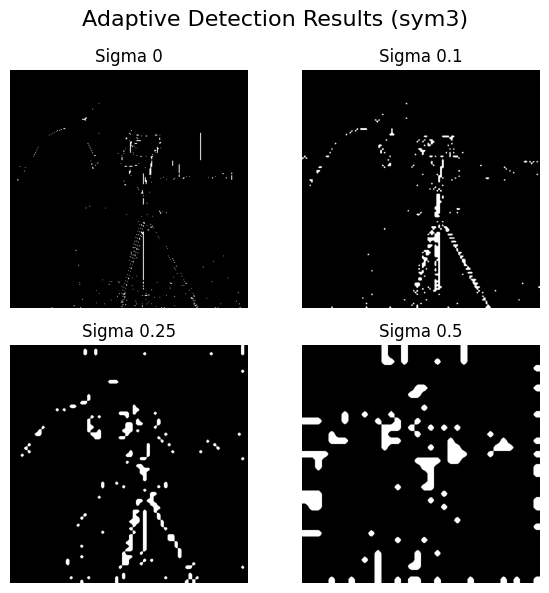

Noise Sigma: 0.006 -> Selected Level: 1
Noise Sigma: 0.096 -> Selected Level: 2
Noise Sigma: 0.207 -> Selected Level: 3
Noise Sigma: 0.333 -> Selected Level: 4


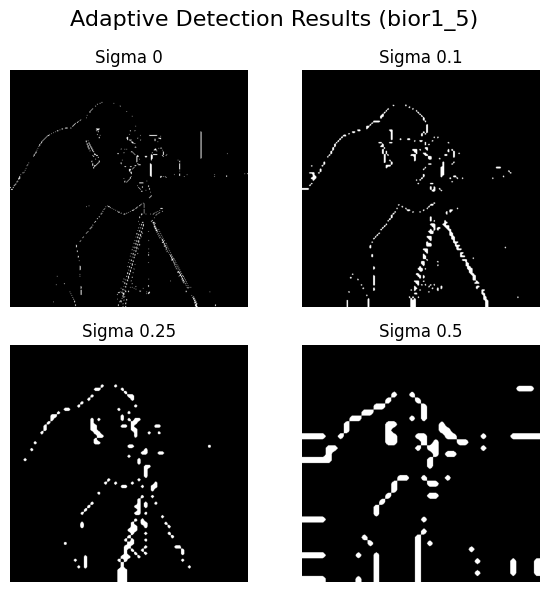

In [6]:
def show_multiple(images, titles, main_title=None, cmap="gray", vmin=0, vmax=1):
    n = len(images)
    cols = 2
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(6, 6))
    if main_title:
        fig.suptitle(main_title, fontsize=16)
    flat_axes = axes.flatten()
    for i, ax in enumerate(flat_axes):
        if i < n:
            ax.imshow(images[i], cmap=cmap, vmin=vmin, vmax=vmax)
            ax.axis("off")
            if titles and i < len(titles):
                ax.set_title(titles[i], fontsize=12)
        else:
            ax.axis("off")
    plt.tight_layout()
    plt.savefig(main_title, dpi=300)
    plt.show()

def target_level(img, wavelet):
    coeffs_measure = pywt.wavedec2(img, wavelet, level=1)
    cD1 = coeffs_measure[-1][2]
    mad = np.median(np.abs(cD1))
    sigma_est = mad / 0.6745
    
    if sigma_est < 0.05:
        return sigma_est, 1
    elif sigma_est < 0.1:
        return sigma_est, 2
    elif sigma_est < 0.25:
        return sigma_est, 3
        
    return sigma_est, 4

def adaptive_edge_detector(img, wavelet='haar'):
    sigma_est, detected_level = target_level(img, wavelet)
        
    print(f"Noise Sigma: {sigma_est:.3f} -> Selected Level: {detected_level}")
    coeffs = pywt.wavedec2(img, wavelet, level=detected_level)
    (cH, cV, cD) = coeffs[1]
    magnitude = np.sqrt(cH**2 + cV**2 + cD**2)
    limit = 0.4 * np.max(magnitude)
    binary_mask = magnitude > limit
    mask_float = binary_mask.astype(np.float32)

    if wavelet == 'haar':
        interpolation_method = cv2.INTER_NEAREST
    else:
        interpolation_method = cv2.INTER_LINEAR
    
    final_edge_map = cv2.resize(mask_float, (img.shape[1], img.shape[0]), 
                                interpolation=interpolation_method)
    return final_edge_map > 0.5

'''
for wavelet in ['haar']:
    for sigma in [0, 0.1, 0.25, 0.5]:
        noisy_img = np.clip(img + sigma * np.random.randn(*img.shape), 0, 1)
        result = adaptive_edge_detector(noisy_img, wavelet)
        show(result, f"Final Result with {wavelet} wavelet. (Sigma {sigma})")
'''

for wavelet in ['haar', 'db2', 'sym3', 'bior1.5']:
    results_to_plot = []
    titles_to_plot = []
    for sigma in [0, 0.1, 0.25, 0.5]:
        noisy_img = np.clip(img + sigma * np.random.randn(*img.shape), 0, 1)
        result = adaptive_edge_detector(noisy_img, wavelet)
        results_to_plot.append(result)
        titles_to_plot.append(f'Sigma {sigma}')
    main_title= f"Adaptive Detection Results (bior1_5)" if wavelet == 'bior1.5' else f"Adaptive Detection Results ({wavelet})"
    show_multiple(results_to_plot, titles_to_plot, main_title=main_title)